## Садиков_3826М1ПМвм1_1
### Лабораторная работа 1: NumPy, SciPy, Matplotlib для задач ML
### Садиков Дамир. 3821М1ПМвм1. 2026

In [1]:
import sys
print(sys.version)

3.10.4 (tags/v3.10.4:9d38120, Mar 23 2022, 23:13:41) [MSC v.1929 64 bit (AMD64)]


## Цель работы

Освоение трёх ключевых библиотек языка Python — NumPy, SciPy и Matplotlib.
1. Освоить представление данных в виде векторов и матриц, как этого требуют алгоритмы машинного обучения
2. Освоение базовых операции линейной алгебры (скалярное произведение, нормы, транспонирование, решение систем линейных уравнений)
3. Визуализация исходных данные, разделяющих поверхностей классификаторов и построение графиков зависимости ошибки от параметров модели

По итогу работы необходимо уметь:
1. Создавать синтетические наборы данных средствами scikit-learn 
2. Производить над ними векторные и матричные операции средствами NumPy
3. Минимизировать функции потерь средствами scipy.optimize
4. Выполнять статистический анализ выборок средствами scipy.stats
5. Строить диаграммы рассеяния, кривые обучения и разделяющие поверхности классификаторов средствами Matplotlib
6. Дополнительно - линейная регрессия «с нуля» через градиентный спуск — для понимания принципов работы библиотечных реализаций

## Теоретическая часть
Роль **NumPy** в машинном обучения: реализованные в данной библиотеке векторные вычисления позволяют ускорить вычисления в 10-100 раз по сравнению с обычными списками Python за счёт использования оптимизированых С и FORTRAN функций и библиотеки BLAS/LAPACK для линейной алгебры. Поэтому основные библиотеки ML построены на основе NumPy и совместимы с ним.

Возможности **SciPy**: библиотека, расширяющая возможности NumPy для научных вычислений. Несколько модулей библиотеки позволяют решать конкретные задачи: scipy.optimize - методы численной оптимизации, scipy.integrate - численное интегрирование, scipy.stats - статистические функции (использований функций распределения и проверка статистических гипотез), scipy.linalg - расширения линейной алгебры (расширяют numpy.linalg), scipy.sparse - работа с разреженными матрицами

**Matplotlib** - одна из основых, и пожалуй самая популярная, библиотек для построения графиков на Python. В контексте ML позволяет строить, в том числе: строить точечные диаграммы для визуализации выборки, отображать поверхности классификаторов, графики для диагностирования переобучения и недообучения

In [2]:
# Импорт основных библиотек
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression

## Практическая часть
### 1.1 Создание синтетических данных для задач классификации и регрессии

In [3]:
# Генерация данных для задачи КЛАССИФИКАЦИИ (2 признака, 2 класса)
X_class, y_class = make_classification(
    n_samples = 200,       # количество объектов
    n_features = 2,        # количество признаков
    n_informative = 2,     # информативные признаки
    n_redundant = 0,       # избыточные признаки
    n_clusters_per_class = 1,
    random_state = 42
)

print("Данные для классификации:")
print(f"X.shape: {X_class.shape}  (объекты × признаки)")
print(f"y.shape: {y_class.shape}  (метки классов)")
print(f"Уникальные классы: {np.unique(y_class)}")
 
# Генерация данных для задачи РЕГРЕССИИ
X_reg, y_reg = make_regression(
    n_samples = 100,
    n_features = 1,        # один признак для визуализации
    noise = 10.0,
    random_state = 42
)
 
print("\nДанные для регрессии:")
print(f"X.shape: {X_reg.shape}")
print(f"y.shape: {y_reg.shape}")

Данные для классификации:
X.shape: (200, 2)  (объекты × признаки)
y.shape: (200,)  (метки классов)
Уникальные классы: [0 1]

Данные для регрессии:
X.shape: (100, 1)
y.shape: (100,)


Продемонстрирован удобный способ создания выборок с помощью sklearn.datasets.make_classification и sklearn.datasets.make_regression

### 1.1.1 Визуализация данных классификации и регрессии

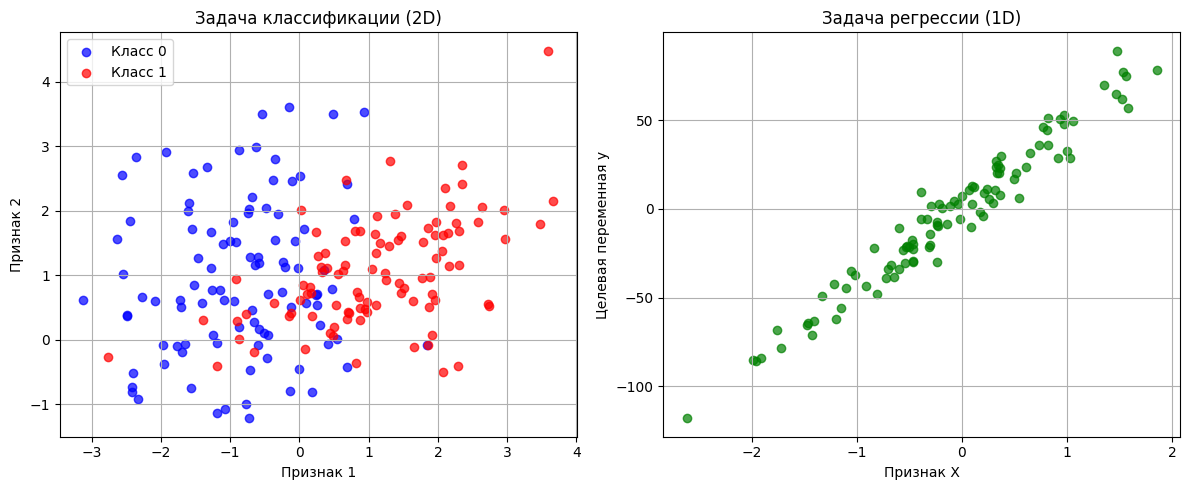

In [4]:
# Создание графика с двумя подграфиками
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
 
# Визуализация данных классификации
ax1.scatter(X_class[y_class==0, 0], X_class[y_class==0, 1],
            color='blue', label='Класс 0', alpha=0.7)
ax1.scatter(X_class[y_class==1, 0], X_class[y_class==1, 1],
            color='red', label='Класс 1', alpha=0.7)
ax1.set_xlabel('Признак 1')
ax1.set_ylabel('Признак 2')
ax1.set_title('Задача классификации (2D)')
ax1.legend()
ax1.grid(True)
 
# Данные для регрессии
ax2.scatter(X_reg, y_reg, color='green', alpha=0.7)
ax2.set_xlabel('Признак X')
ax2.set_ylabel('Целевая переменная y')
ax2.set_title('Задача регрессии (1D)')
ax2.grid(True)
 
plt.tight_layout()
plt.show()

В данном примере представлены способы визуализации исходных данных для задач классификации и регрессии с помощью Matplotlib. Использовались возможности удобных срезов в массивах NumPy (Более подробно будут рассмотрены далее)

### 1.2 Основные операции с векторами для ML

In [5]:
# Создание векторов
a = np.array([1, 2, 3, 4])
b = np.array([5, 6, 7, 8])
print(f'Вектор a = {a}')
print(f'Вектор b = {b}')

# Скалярное произведение (dot product)
dot_product = np.dot(a, b) # или a @ b
print(f"Скалярное произведение a·b = {dot_product}")
 
# Евклидова норма (L2)
euclidean_norm = np.sqrt(np.sum(a ** 2)) # или np.linalg.norm(a)
print(f"Евклидова норма a = {euclidean_norm:.4f}")

# Манхэттенская норма (L1)
manhattan_norm = np.sum(np.abs(a))
print(f"Манхэттенская норма a = {manhattan_norm}")
 
# Угол между векторами (косинусное расстояние)
cos_angle = dot_product / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"Косинус угла между a и b = {cos_angle:.4f}")

Вектор a = [1 2 3 4]
Вектор b = [5 6 7 8]
Скалярное произведение a·b = 70
Евклидова норма a = 5.4772
Манхэттенская норма a = 10
Косинус угла между a и b = 0.9689


Обзор основых операций NumPy: создание векторов, скалярное произведение, сумма элементов, модуль элементов, вычисление длины вектора

### 1.2.1 Вычисление расстояний для kNN

In [6]:
def euclidean_distance(x1, x2):
    """
    Вычисляет евклидово расстояние между двумя векторами.
 
    Параметры:
    x1, x2 — numpy массивы одинаковой длины
 
    Возвращает:
    расстояние (скаляр)
    """
    diff = x1 - x2
    return np.sqrt(np.dot(diff, diff))

x1 = np.array([1, 2, 3])
x2 = np.array([4, 5, 6])
expected = np.linalg.norm(x1 - x2)
 
print(f"Расстояние между x1 и x2 c помошью функции: {euclidean_distance(x1, x2):.4f}")
print(f"Ожидаемое значение:                         {expected:.4f}")

Расстояние между x1 и x2 c помошью функции: 5.1962
Ожидаемое значение:                         5.1962


Реализация методами NumPy вычисления евклидовой нормы и сравнение с библиотечной реализацией

### 1.3 Матрицы для ML-задач

In [7]:
# Матрица признаков: N объектов × d признаков
X = np.array([
    [1.0, 2.0, 3.0],  # объект 1
    [4.0, 5.0, 6.0],  # объект 2
    [7.0, 8.0, 9.0],  # объект 3
    [10.0, 11.0, 12.0]  # объект 4
])
 
print(f"Матрица признаков X (4×3):\n{X}")
print(f"Размерность (Кол-во объектов × Кол-во признаков): {X.shape}")
 
# Вектор весов (для линейной модели)
w = np.array([0.5, 1.0, 2.0])
# bias (смещение)
b = 1.5

print(f"Вектор весов w: {w}")
print(f"Смещение (bias) b: {b}")

# Линейная модель: y = X·w + b
predictions = X @ w + b
print(f"Предсказания линейной модели X @ w + b: {predictions}")
 

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print(f"\nA:\n{A}")
print(f"B:\n{B}")
# Сложение матриц (поэлементно)
print(f"A + B =\n{A + B}")
 
# Транспонирование (A.T)
print(f"A^T =\n{A.T}")

# Умножение матриц (важно: A @ B, а не A * B)
C = A @ B
print(f"Умножение матриц по правилам матричного умножения A @ B =\n{C}")

D = A * B
print(f"Поэлементное умножение матриц A * B = \n{D}")

Матрица признаков X (4×3):
[[ 1.  2.  3.]
 [ 4.  5.  6.]
 [ 7.  8.  9.]
 [10. 11. 12.]]
Размерность (Кол-во объектов × Кол-во признаков): (4, 3)
Вектор весов w: [0.5 1.  2. ]
Смещение (bias) b: 1.5
Предсказания линейной модели X @ w + b: [10.  20.5 31.  41.5]

A:
[[1 2]
 [3 4]]
B:
[[5 6]
 [7 8]]
A + B =
[[ 6  8]
 [10 12]]
A^T =
[[1 3]
 [2 4]]
Умножение матриц по правилам матричного умножения A @ B =
[[19 22]
 [43 50]]
Поэлементное умножение матриц A * B = 
[[ 5 12]
 [21 32]]


Создание и основные операции с матрицами в NumPy. Демонстрация различия умножения с помощью @ и *

### 1.3.1 Решение системы линейных уравнений

In [8]:
from numpy.linalg import inv, solve

# Дано
X = np.array([
    [1, 1],
    [1, 2],
    [1, 3]
])  # матрица признаков (с добавленным столбцом единиц для bias)
y = np.array([2, 3, 4])  # целевая переменная

print(f"X = \n{X}")
print(f"y = {y}")
# Нормальное уравнение: (X^T @ X) @ w = (X^T) @ y
# w = (X^T·X)^(-1)·X^T·y
print("(X^T @ X) @ w = (X^T) @ y")
print("w = inv(X^T @ X) @ X^T @ y")

# 3. Решаем систему
w = inv(X.T @ X) @ X.T @ y # или solve(X.T @ X, X.T @ y)
print(f"Вектор весов w = {w}")
 
# 4. Проверка: предсказания для X
predictions = X @ w
print(f"Предсказания: {predictions}")
print(f"Истинные y:   {y}")

X = 
[[1 1]
 [1 2]
 [1 3]]
y = [2 3 4]
(X^T @ X) @ w = (X^T) @ y
w = inv(X^T @ X) @ X^T @ y
Вектор весов w = [1. 1.]
Предсказания: [2. 3. 4.]
Истинные y:   [2 3 4]


Вычисление решения нормального уравнения средствами NumPy. Таким образом демонстрируется метод наименьших квадратов для переопределенной системы

### 1.4 Срезка (slicing) и индексация данных

In [9]:
# Создаём матрицу 10×5 со случайными данными
np.random.seed(42)
data = np.random.rand(10, 5) * 100
print("Исходные данные:")
print(data)
 
# Извлечение первых 3 объектов (строк)
first_3 = data[:3, :]
print("\nПервые 3 объекта:")
print(first_3)
 
# Извлечение признаков 1, 3, 5
selected_features = data[:, [0, 2, 4]]
print("\nПризнаки 1, 3, 5:")
print(selected_features)
 
# Извлечение объектов со значением признака > 50
mask = data[:, 0] > 50
filtered = data[mask, :]
print(f"\nОбъектов с 1-м признаком > 50: {len(filtered)}")
 
# Разделение на обучающую и тестовую выборки (ручная реализация)
N = len(data)
indices = np.random.permutation(N)
train_idx = indices[:int(0.7 * N)]
test_idx = indices[int(0.7 * N):]
 
X_train = data[train_idx, :]
X_test = data[test_idx, :]
print(f"Размер обучающей выборки: {len(X_train)}")
print(f"Размер тестовой выборки:  {len(X_test)}")

Исходные данные:
[[37.45401188 95.07143064 73.19939418 59.86584842 15.60186404]
 [15.59945203  5.80836122 86.61761458 60.11150117 70.80725778]
 [ 2.05844943 96.99098522 83.24426408 21.23391107 18.18249672]
 [18.34045099 30.4242243  52.47564316 43.19450186 29.12291402]
 [61.18528947 13.94938607 29.21446485 36.63618433 45.60699842]
 [78.51759614 19.96737822 51.42344384 59.24145689  4.64504127]
 [60.75448519 17.05241237  6.5051593  94.88855373 96.56320331]
 [80.83973481 30.46137692  9.7672114  68.42330265 44.01524937]
 [12.20382348 49.51769101  3.43885211 90.93204021 25.87799816]
 [66.25222844 31.17110761 52.00680212 54.67102793 18.48544555]]

Первые 3 объекта:
[[37.45401188 95.07143064 73.19939418 59.86584842 15.60186404]
 [15.59945203  5.80836122 86.61761458 60.11150117 70.80725778]
 [ 2.05844943 96.99098522 83.24426408 21.23391107 18.18249672]]

Признаки 1, 3, 5:
[[37.45401188 73.19939418 15.60186404]
 [15.59945203 86.61761458 70.80725778]
 [ 2.05844943 83.24426408 18.18249672]
 [18.34

Пример демонстрирует возможности NumPy по срезке (выбору) строк и столбцов матриц

### 2.1 Минимизация функции потерь (градиентный спуск)

In [10]:
from scipy.optimize import minimize
import numpy as np

# Генерация синтетических данных
np.random.seed(42)
X = np.random.rand(100, 1) * 10
y = 2.5 * X + 1.0 + np.random.randn(100, 1) * 2.0
 
# Функция потерь: MSE
def mse_loss(params, X, y):
    w, b = params
    predictions = w * X.flatten() + b
    diff = predictions - y.flatten()
    return np.dot(diff, diff)
 
# Минимизация Фунции потерь с помощью scipy.optimize.minimize
initial_params = [0.0, 0.0]
result = minimize(mse_loss, initial_params, args=(X, y))
 
print("Результат оптимизации:")
print(f"  w = {result.x[0]:.4f}")
print(f"  b = {result.x[1]:.4f}")
print(f"MSE = {result.fun:.4f}")
 
# Сравнение с точным решением (через нормальное уравнение)
X_design = np.hstack([X, np.ones((len(X), 1))])
w_exact = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y
print(f"\nТочное решение (нормальное уравнение):")
print(f"  w = {w_exact[0, 0]:.4f}")
print(f"  b = {w_exact[1, 0]:.4f}")

Результат оптимизации:
  w = 2.4080
  b = 1.4302
MSE = 322.6338

Точное решение (нормальное уравнение):
  w = 2.4080
  b = 1.4302


Другой способ минимизации суммы квадратов невязок: градиентный спуск. Вычисление средствами SciPy и сравнение с непосредственным решением нормального уравнения

### 2.1.1 Минимизация для логистической регрессии

In [11]:
# Генерация данных для классификации
from sklearn.datasets import make_classification
X_class, y_class = make_classification(n_samples=200, n_features=1,
                                       n_classes=2, n_informative=1,
                                       n_redundant=0, random_state=42,
                                       n_clusters_per_class=1)
print(f"X_class.shape = {X_class.shape}")
print(f"y_class.shape = {y_class.shape}")

# Функция потерь для логистической регрессии
def logistic_loss(params, X, y):
    w, b = params
    z = w * X.flatten() + b
    # sigmoid: 1 / (1 + exp(-z))
    p = 1 / (1 + np.exp(-z))
    # BCE: - (y*log(p) + (1-y)*log(1-p))
    loss = -np.mean(y * np.log(p + 1e-10) + (1 - y) * np.log(1 - p + 1e-10))
    return loss
 
# Оптимизация
result = minimize(logistic_loss, [0.0, 0.0], args=(X_class, y_class))
print(f"w = {result.x[0]:.4f}, b = {result.x[1]:.4f}")
print(f"Минимальное значение BCE = {result.fun:.4f}")

X_class.shape = (200, 1)
y_class.shape = (200,)
w = 14.5163, b = -3.0769
Минимальное значение BCE = 0.0470


Нахождение точки минимума для логистической регрессии средствами scipy.optimize. В отличии от минимизации MSE логистическая регрессия не имеет решения методами линейной алгебры, поэтому требуется минимизация численными методами

### 2.2 Статистический анализ данных

In [12]:
from scipy import stats
import numpy as np
 
# Генерация выборки
data = np.random.normal(loc=0, scale=1, size=1000)
 
# Основные статистики
mean = np.mean(data)
std = np.std(data)
median = np.median(data)
 
print(f"Среднее: {mean:.4f}")
print(f"Стандартное отклонение: {std:.4f}")
print(f"Медиана: {median:.4f}")
 
# Проверка нормальности (тест Шапиро-Уилка)
# Используется для проверки предположений о распределении данных
statistic, p_value = stats.shapiro(data[:100])  # для больших выборок берём часть
print(f"\nТест Шапиро-Уилка: p-value = {p_value:.4f}")
if p_value > 0.05:
    print("  → данные распределены нормально (не отвергаем H0)")
else:
    print("  → данные не распределены нормально (отвергаем H0)")
 
# Доверительный интервал для среднего
# Используется: для оценки неопределённости предсказаний
from scipy.stats import t
confidence_level = 0.95
n = len(data)
se = std / np.sqrt(n)  # стандартная ошибка среднего
t_critical = t.ppf((1 + confidence_level) / 2, df=n-1)
ci_lower = mean - t_critical * se
ci_upper = mean + t_critical * se
print(f"\n95% доверительный интервал для среднего: [{ci_lower:.4f}, {ci_upper:.4f}]")



Среднее: 0.0591
Стандартное отклонение: 0.9979
Медиана: 0.0570

Тест Шапиро-Уилка: p-value = 0.2378
  → данные распределены нормально (не отвергаем H0)

95% доверительный интервал для среднего: [-0.0028, 0.1211]


Демонстрация статистического анализа выборки для проверки "нормальности". Полезно при оценке исходной выборки и выбора дальнейшего метода обработки данных

### 3.1 Визуализация классификатора

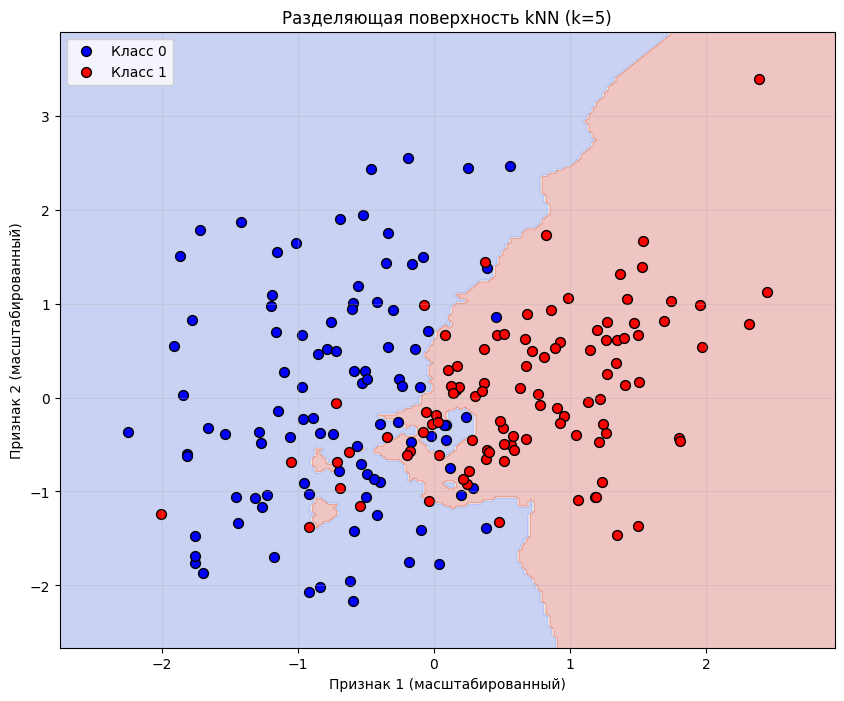

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
 
# Генерация данных
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=200, n_features=2,
                           n_informative=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=42)
 
# Масштабирование (важно для kNN!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
 
# Обучение kNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_scaled, y)
 
# Создание сетки для визуализации разделяющей поверхности
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
 
# Предсказание для всех точек сетки
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
 
# Визуализация
plt.figure(figsize=(10, 8))
 
# 1. Разделяющая поверхность
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
 
# 2. Данные
plt.scatter(X_scaled[y==0, 0], X_scaled[y==0, 1],
            color='blue', label='Класс 0', edgecolors='k', s=50)
plt.scatter(X_scaled[y==1, 0], X_scaled[y==1, 1],
            color='red', label='Класс 1', edgecolors='k', s=50)
 
plt.xlabel('Признак 1 (масштабированный)')
plt.ylabel('Признак 2 (масштабированный)')
plt.title('Разделяющая поверхность kNN (k=5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Демонстрация разделяющей поверхности при использовании классификатора kNN (k = 5)

### 3.2 Графики ошибок и диагностика переобучения

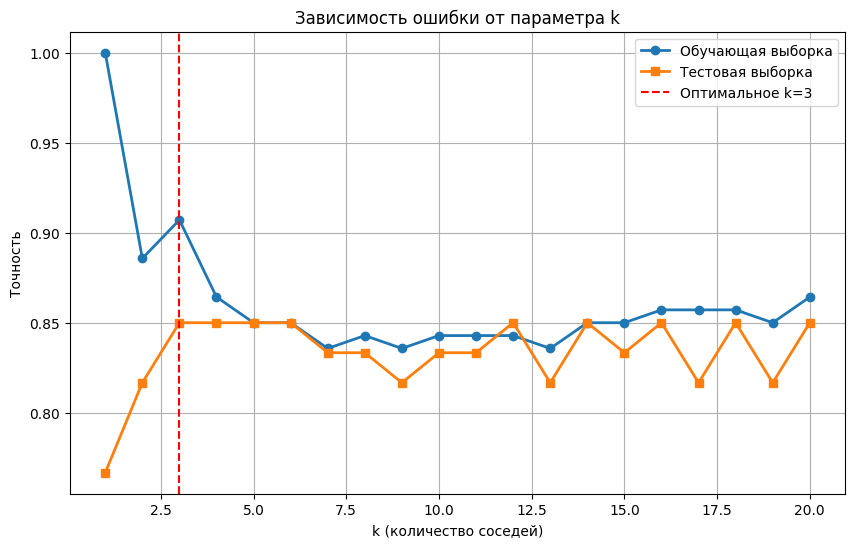


ДИАГНОСТИКА ПЕРЕОБУЧЕНИЯ
k= 1: Train=1.000, Test=0.767, Разница=0.233
k= 3: Train=0.907, Test=0.850, Разница=0.057
k= 5: Train=0.850, Test=0.850, Разница=0.000
k=10: Train=0.843, Test=0.833, Разница=0.010
k=15: Train=0.850, Test=0.833, Разница=0.017


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
 
# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)
 
# Эксперимент с разными k
k_values = range(1, 21)
train_scores = []
test_scores = []
 
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))
 
# График
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, 'o-', label='Обучающая выборка', linewidth=2)
plt.plot(k_values, test_scores, 's-', label='Тестовая выборка', linewidth=2)
plt.xlabel('k (количество соседей)')
plt.ylabel('Точность')
plt.title('Зависимость ошибки от параметра k')
plt.legend()
plt.grid(True)
plt.axvline(x=k_values[np.argmax(test_scores)], color='red',
            linestyle='--', label=f'Оптимальное k={k_values[np.argmax(test_scores)]}')
plt.legend()
plt.show()
 
# Анализ переобучения
print("\n" + "="*50)
print("ДИАГНОСТИКА ПЕРЕОБУЧЕНИЯ")
print("="*50)
for k in [1, 3, 5, 10, 15]:
    diff = train_scores[k-1] - test_scores[k-1]
    print(f"k={k:2d}: Train={train_scores[k-1]:.3f}, Test={test_scores[k-1]:.3f}, Разница={diff:.3f}")


Перебор гиперпараметра k классификатора kNN. При малых k заметно переобучение модели: более точные результаты для обучающей выборки, чем для тестовой: модель вместо закономерности "запоминает" обучающую выборку. При увеличении k происходит увеличение точности предсказаний на тестовой выборке и сближение точности предсказаний на обучающей и тестовой выборках. Оптиамальные значения в данном примере достигаются при k = 3-6. При дальнейшем увеличении k могут наблюдаться ухудшение точности на обучающей и тестовой выборках (модель будет слишком обобщать, будет наблюдаться недообучение)

### 3.3 Визуализация регрессии

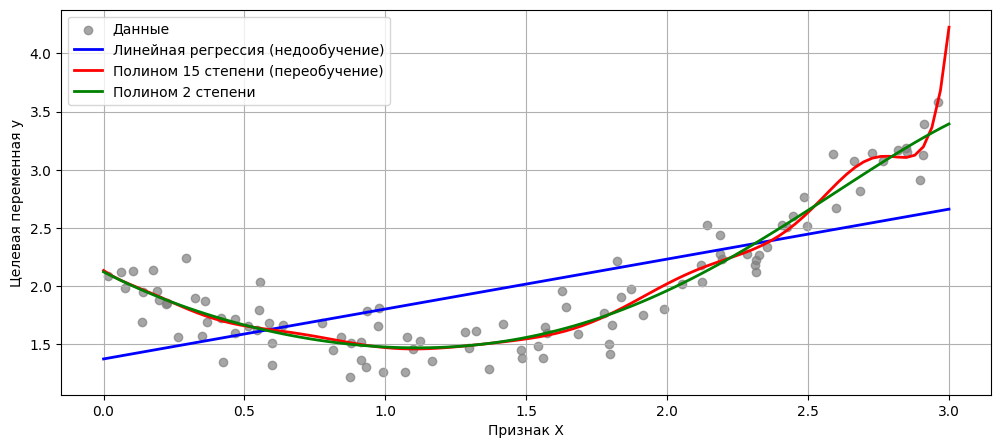

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
 
# Генерация данных
np.random.seed(42)
X_reg = np.random.rand(100, 1) * 3
y_reg = 0.5 * X_reg.flatten() ** 2 - X_reg.flatten() + 2 + np.random.randn(100) * 0.2
 
# Линейная регрессия (недообучение)
lr = LinearRegression()
lr.fit(X_reg, y_reg)

# Полиномиальная регрессия (Полиномом 2 степени)
poly_2 = Pipeline([
    ('poly', PolynomialFeatures(degree=5)),
    ('linear', LinearRegression())
])
poly_2.fit(X_reg, y_reg)

# Полиномиальная регрессия (степень 15 — переобучение)
poly_15 = Pipeline([
    ('poly', PolynomialFeatures(degree=15)),
    ('linear', LinearRegression())
])
poly_15.fit(X_reg, y_reg)
 
# Предсказания на сетке
X_grid = np.linspace(0, 3, 100).reshape(-1, 1)
y_lr = lr.predict(X_grid)
y_poly_2 = poly_2.predict(X_grid)
y_poly_15 = poly_15.predict(X_grid)
 
# Визуализация
plt.figure(figsize=(12, 5))
 
plt.scatter(X_reg, y_reg, color='gray', alpha=0.7, label='Данные')
plt.plot(X_grid, y_lr, 'b-', linewidth=2, label='Линейная регрессия (недообучение)')
plt.plot(X_grid, y_poly_15, 'r-', linewidth=2, label='Полином 15 степени (переобучение)')
plt.plot(X_grid, y_poly_2, 'g-', linewidth=2, label='Полином 2 степени')
plt.xlabel('Признак X')
plt.ylabel('Целевая переменная y')
plt.legend()
plt.grid(True)
plt.show()


Визулизация регрессии при подборе полиномов разных степеней. При использовании линейной модели происходит недообучение: модель не способна передать кривизну входных данных. При использовании полинома слишоком большой степени (в данном случае 15) наблюдается переобучение: модель слишком сильно подстраивается под ошибки входных данных. При использовании полинома второй степени (что совпадает с распределением входных данных) модель подстраивается под входные данные сбалансированно 

### 4. Реализация линейной регрессии «с нуля»

Среднеквадратичная ошибка: 81.9732
Коэффициент детерминации R²: 0.9895


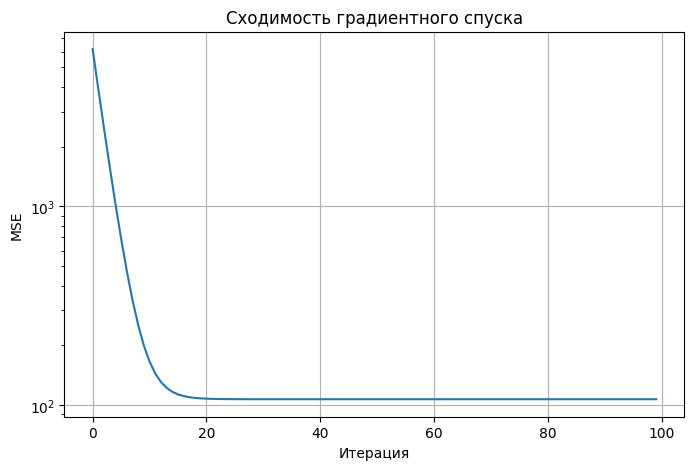

MSE (градиентный спуск): 81.9732
MSE (Sklearn):          81.9732
Разница:                0.000002


In [16]:
import numpy as np
import matplotlib.pyplot as plt
 
class LinearRegressionGD:
    """
    Линейная регрессия, обучаемая градиентным спуском.
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []
 
    def fit(self, X, y):
        """Обучение модели."""
        n_samples, n_features = X.shape
 
        # Инициализация
        self.weights = np.zeros(n_features)
        self.bias = 0
 
        for i in range(self.n_iterations):
            # 1. Предсказание
            y_pred = X @ self.weights + self.bias
 
            # 2. Вычисление градиента
            # dL/dw = (2/N) * X^T · (y_pred - y)
            dw = (2 / n_samples) * X.T @ (y_pred - y)
            # dL/db = (2/N) * sum(y_pred - y)
            db = (2 / n_samples) * np.sum(y_pred - y)
 
            # 3. Обновление весов
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # 4. Предсказание с текущими весами
            y_pred = X @ self.weights + self.bias

            # 5. Сохранение ошибки
            loss = np.mean((y_pred - y) ** 2)
            self.loss_history.append(loss)
 
        return self
 
    def predict(self, X):
        """Предсказание."""
        return X @ self.weights + self.bias
 
# Тестирование
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
 
# Генерация данных
X, y = make_regression(n_samples=200, n_features=5, noise=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
 
# Масштабирование (важно для сходимости GD)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
 
# Обучение
model = LinearRegressionGD(learning_rate=0.1, n_iterations=100)
model.fit(X_train_scaled, y_train)
 
# Оценка
y_pred = model.predict(X_test_scaled)
mse = np.mean((y_test - y_pred) ** 2)
r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
 
print(f"Среднеквадратичная ошибка: {mse:.4f}")
print(f"Коэффициент детерминации R²: {r2:.4f}")
 
# График сходимости
plt.figure(figsize=(8, 5))
plt.plot(model.loss_history)
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Сходимость градиентного спуска')
plt.grid(True)
plt.yscale('log')
plt.show()

from sklearn.linear_model import LinearRegression
 
# Scikit-learn реализация
sk_lr = LinearRegression()
sk_lr.fit(X_train_scaled, y_train)
sk_pred = sk_lr.predict(X_test_scaled)
sk_mse = np.mean((y_test - sk_pred) ** 2)
 
print(f"MSE (градиентный спуск): {mse:.4f}")
print(f"MSE (Sklearn):          {sk_mse:.4f}")
print(f"Разница:                {abs(mse - sk_mse):.6f}")

Реализована линейная регрессия через градиентный спуск на основе библиотеки NumPy. График изменения ошибки позволяет увидеть что ошибка при использовании градиентного спуска для задачи линейной регрессии убывает экспоненциально. Сравнение с эталонной библиотечной реализацией также подтверждает правильность реализации алгоритма

## Анализ результатов

Анализ переобучения на примерах классификации методом kNN и полиномиальной регрессии. Эксперименты показали что от выбора гиперпараметров сильно зависит качество обучение модели как в задачах классификации и регресии. При переобучении модель слишком сильно подстраивается под обучаемую выборку, что приводит к значительному ухудшению результатов на тестовой. При недообучении модель наоборот слишком обобщает обучаемую выборку, что приводит к ухудшению результатов и на обучаемой и на тестовой выборках. На примере линейной модели для квадратичной зависимости в задаче регресии можно показать пример недообучения: из-за линейнойсти модель не может учесть кривизну функции

Поведение градиентного спуска. При правильном применении градиентного спуска ошибка с каждой итерацией должна уменьшаться. Learning_rate может значительно влиять на сходимость: при слишком малых значениях будет увеличиваться требуемое количество итераций, при постановке слишком высокого значения на каждой итерации наоборот может происходить слишком большой шаг в направлении антиградиента, из-за чего можно "проскочить" оптимальную точку. Масштабирование параметров входных данных также может влиять на скорость сходимости. Из методов оптимизации известно что, в общем случае, нахождение решения для более "сферических" выпуклых функции градиентым спуском находится быстрее чем для сильно вытянутых.

Сравнение градиентного спуска по скорости и точности. Решение нормального уравнения позволяет найти точное решение в случае минимизации MSE для получения линейной регресии. Градиентный спуск является численным приближенным методом, однако может быть более удачным выбором на практике, так как не требует дорогостоящей операции вычисления обратной матрицы, что особенно критично для задач с большим количеством параметров.

## Выводы

Были освоены ключевых для машинного обучения библиотек языка Python — NumPy, SciPy и Matplotlib.
Получены практические навыки необходимые для дальнейших работ по машинному обучению: создание синтетических наборов данных, работа с векторными операциями, минимизация функций потерь, статистический анализ выборок, построение диаграмм и графиков средствами Matplotlib.
Для понимания принципов работы библиотечных реализаций были реализована линейная регрессия с использованием только NumPy

## Контрольные вопросы

1. ***Почему NumPy значительно быстрее Python-списков для численных операций?*** NumPy использует оптимизированные реализации функций, написанные на С и Fortran, в то время как при работе с Python-списками происходит поэлементная итерация
2. ***Какова роль матричного умножения X @ w в линейной регрессии?*** Матричное умножение является основной операцией в линейной регрессии, так как именно оно позволяет получить предсказания модели! В случае обучения оно также лежит в основе вычислений
3. ***Что такое «проклятие размерности» и как оно связано с матричным представлением данных?*** Проклятие размерности подразумевает увеличение сложности вычислительных алгоритмов при увеличении размерности. К примеру при нахождении решения нормального уравнения требуется нахождение обратной матрицы, что является сложной вычислительной операцией, сильно растущей при увеличении размера входных данных
4. ***Почему нормализация данных важна для методов, использующих расстояния (kNN)?*** Без нормализации расстояния будут в разном масштабе, из-за этого расстояния по одному из параметров могут значительно сильнее влиять на вычесленное расстояние чем другие. Чтобы такого не происходило требуется нормализация
5. ***Как график ошибок train vs test помогает диагностировать переобучение?*** На графике можно наглядно увидеть переобучение: необходимо обратить внимание на разницу между графиком train и графикм test. При переобучении точность на train значительно выше чем на test
6. ***В чём отличие X @ w от X * w в NumPy?*** @ осуществляет умножение по правилам матричного умножения, а * осуществляет поэлементное умножение
7. ***Какие численные методы оптимизации реализованы в scipy.optimize, и в каких случаях применять каждый из них?*** В scipy.optimize реализовано несколько численных методов оптимизации. По умолчанию используется BFGS. Для шумных и/или невыпуклых функций лучше подходит Nelder-Mead. Для задач где градиентный спуск становится слишком медленным рекомендуется использовать стохастический градиентный спуск SGD и его варианты.